# QFF 2026 Phase 2 — Quantum Optimization Track
## PS-O1: Quantum Optimization of Network Partitioning Using QAOA
**Problem Statement:** PS-O1 (Max-Cut on a 6-Vertex Graph Motivated by 5G Network Partitioning)  
**Team Identifier:** `QFF2026_RESEARCH_TEAM` (*Pending Phase 1 Official Registration Confirmation*)  
**Execution Environment:** Python 3.11 | Qiskit 2.6.1 | Qiskit Aer 0.18.2  
**Simulation Notice:** Classical simulation via Qiskit Aer (`AerSimulator`) with realistic depolarizing and readout noise; no physical QPU hardware used.  
**Ground Truth:** Exact Classical Optimum $C^* = 22$ | Uniform Random Baseline $r = 0.6136$  

---
### Notebook Outline
1. **Environment & Verification:** Check Qiskit, Aer, basis gates, and noise settings.
2. **Problem Definition & Formulation:** Locked 6-vertex, 9-edge weighted graph ($W=27$) and QUBO derivation.
3. **Classical Ground Truth:** Exhaustive enumeration over all $2^6=64$ bitstrings establishing $C^* = 22$.
4. **Objective 1 (Bell-State Tomography on Processor D):** Verification of $|\Phi^+\rangle$ state on adjacent ($d=1$) and distant ($d=4$) physical pairs.
5. **Objective 2 (Processor D Architecture):** Official validation and bottleneck resolution over Processor B.
6. **Objective 3 (QAOA Multi-Restart Optimization & Benchmarking):** Mandatory seeds $[0, 1, 2, 3, 4]$ and cross-processor evaluation (A, B, D).
7. **Results & Scientific Figures:** Rendered tables and publication-grade visualizations.


In [1]:
# Section 1: Environment Verification
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
import qiskit
from qiskit import QuantumCircuit
import qiskit_aer

import qff_phase2
from qff_phase2 import (
    BASIS_GATES,
    OPT_LEVEL,
    SEED,
    SHOTS,
    P1_DEPOL,
    P2_DEPOL,
    P_READOUT,
    PROCESSOR_A,
    PROCESSOR_B,
    load_processor,
    validate_processor_d,
    circuit_metrics,
    transpile_for,
    simulator,
    counts_to_x,
)

print(f"Python Version:     {sys.version.split()[0]}")
print(f"Qiskit Version:     {qiskit.__version__}")
print(f"Qiskit Aer Version: {qiskit_aer.__version__}")
print(f"Basis Gates:        {BASIS_GATES}")
print(f"Transpiler Opt:     Level {OPT_LEVEL} (SABRE, Seed {SEED})")
print(f"Official Noise:     p1={P1_DEPOL}, p2={P2_DEPOL}, p_readout={P_READOUT}")


Python Version:     3.11.9
Qiskit Version:     2.6.1
Qiskit Aer Version: 0.18.2
Basis Gates:        ['rz', 'sx', 'x', 'cx']
Transpiler Opt:     Level 1 (SABRE, Seed 42)
Official Noise:     p1=0.001, p2=0.005, p_readout=0.01


# Section 2: Problem Definition, QUBO & Classical Ground Truth
The Max-Cut objective for graph $G=(V, E, w)$ is:
$$C(x) = \sum_{(u,v) \in E} w_{uv} (x_u + x_v - 2 x_u x_v)$$
Minimizing $-C(x)$ defines the QUBO form: $x^T Q x$.


=== EXACT CLASSICAL GROUND TRUTH ===
Vertices:               6
Edges:                  9 (Total Weight W = 27)
Exact Maximum Cut C*:   22
Optimal Assignments:    [(1, 1, 0, 1, 0, 0), (0, 0, 1, 0, 1, 1)]
Optimal Bitstrings:     ['001011', '110100']
Uniform Random Cut:     13.5000 (AR = 0.6136)
Random P_opt:           0.0312 (2/64)


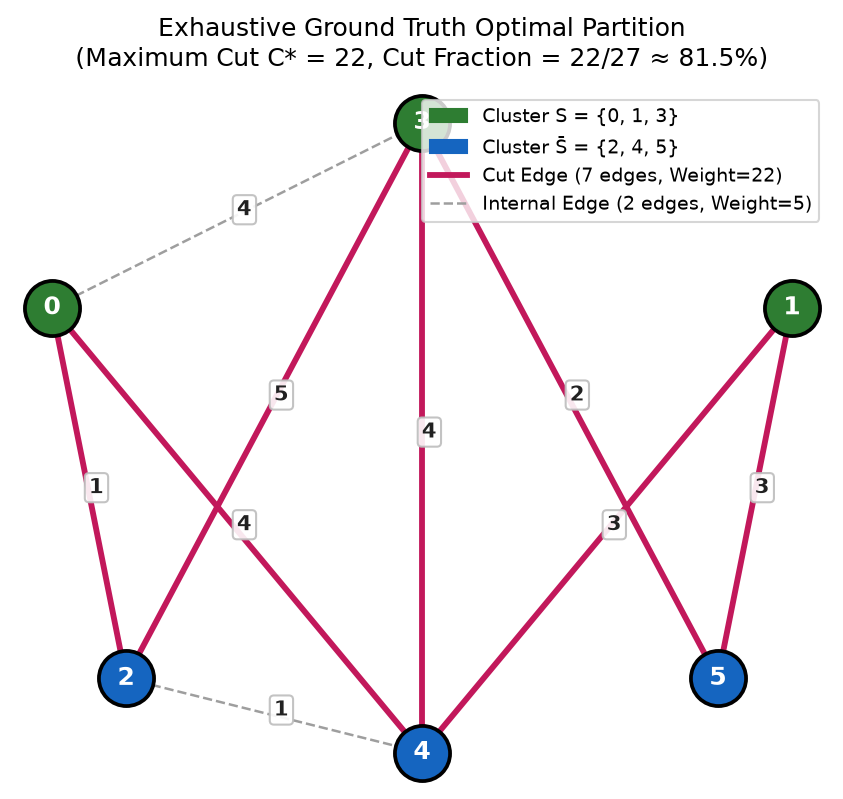

In [2]:
# Section 3: Exhaustive Classical Ground Truth Enumeration
from src.problem_model import LOCKED_EDGES, NUM_VERTICES, TOTAL_WEIGHT
from src.classical_baseline import solve_exhaustive

classical_res = solve_exhaustive(LOCKED_EDGES)
print("=== EXACT CLASSICAL GROUND TRUTH ===")
print(f"Vertices:               {NUM_VERTICES}")
print(f"Edges:                  {len(LOCKED_EDGES)} (Total Weight W = {TOTAL_WEIGHT})")
print(f"Exact Maximum Cut C*:   {classical_res['max_cut']}")
print(f"Optimal Assignments:    {classical_res['optimal_assignments']}")
print(f"Optimal Bitstrings:     {classical_res['optimal_bitstrings']}")
print(f"Uniform Random Cut:     {classical_res['random_mean_cut']:.4f} (AR = {classical_res['random_approx_ratio']:.4f})")
print(f"Random P_opt:           {classical_res['random_p_opt']:.4f} ({classical_res['optimal_count']}/64)")

display(Image(filename="results/figures/network_partitioning_graph.png"))


# Section 4: Objective 1 — Bell-State Preparation and Tomography
We prepare $|\Phi^+angle = (|00angle + |11angle)/\sqrt{2}$ on Processor D:
- **Adjacent physical pair:** $(0, 2)$ at shortest-path distance $d=1$ (1 CX)
- **Maximally separated pair:** $(0, 7)$ at shortest-path distance $d=4$ (10 CX via ancillary ring)
Evaluated across XX, YY, ZZ bases (4096 shots/basis) under ideal and official noisy simulation.


=== Bell State Verification Summary (results/tables/bell.csv) ===


,pair_type,qubit_pair,pair_distance,condition,cx_count,exp_XX,exp_YY,exp_ZZ,fidelity,fidelity_se
0,near,"(0,2)",1,ideal,1,1.000000,-1.000000,1.000000,1.000000,0.000000
1,near,"(0,2)",1,noisy,1,0.945801,-0.952148,0.955078,0.963257,0.002092
2,far,"(0,7)",4,ideal,10,1.000000,-1.000000,1.000000,1.000000,0.000000
3,far,"(0,7)",4,noisy,10,0.924316,-0.903809,0.939941,0.942017,0.002607



=== All 12 Bell Measurement Circuits (results/tables/bell_circuits.csv) ===


,circuit_id,circuit_key,pair_type,qubit_pair,distance,condition,measurement_basis,cx_gates,shots,correlator_value,correlator_se
0,1,near_0_2_ideal_XX,near,"(0,2)",1,ideal,XX,1,4096,1.000000,0.000000
1,2,near_0_2_ideal_YY,near,"(0,2)",1,ideal,YY,1,4096,-1.000000,0.000000
2,3,near_0_2_ideal_ZZ,near,"(0,2)",1,ideal,ZZ,1,4096,1.000000,0.000000
3,4,near_0_2_noisy_XX,near,"(0,2)",1,noisy,XX,1,4096,0.945801,0.005074
4,5,near_0_2_noisy_YY,near,"(0,2)",1,noisy,YY,1,4096,-0.952148,0.004776
5,6,near_0_2_noisy_ZZ,near,"(0,2)",1,noisy,ZZ,1,4096,0.955078,0.004631
6,7,far_0_7_ideal_XX,far,"(0,7)",4,ideal,XX,10,4096,1.000000,0.000000
7,8,far_0_7_ideal_YY,far,"(0,7)",4,ideal,YY,10,4096,-1.000000,0.000000
8,9,far_0_7_ideal_ZZ,far,"(0,7)",4,ideal,ZZ,10,4096,1.000000,0.000000
9,10,far_0_7_noisy_XX,far,"(0,7)",4,noisy,XX,10,4096,0.924316,0.005963


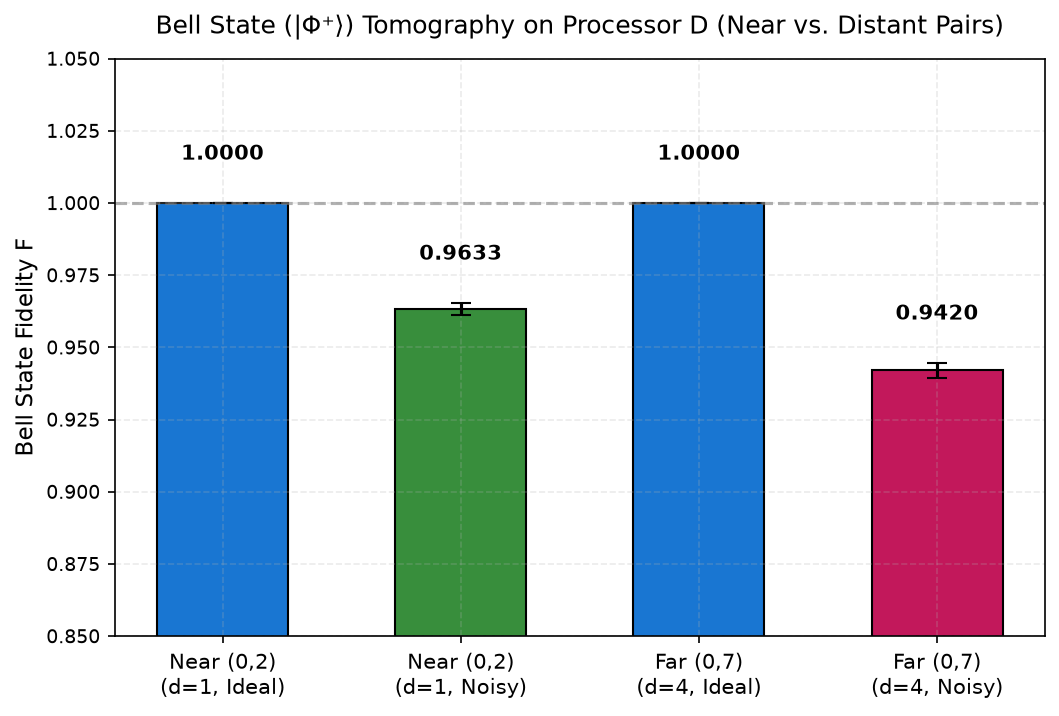

In [3]:
# Section 4.1: Bell-State Tomography Execution & Data Display
from src.bell_verification import run_bell_verification

bell_results = run_bell_verification(
    processor_path="processors/processor_D.json",
    near_pair=(0, 2),
    far_pair=(0, 7),
    output_csv_path="results/tables/bell.csv",
    output_circuits_csv="results/tables/bell_circuits.csv",
    output_raw_counts="results/raw/bell_counts.json",
)

df_bell = pd.read_csv("results/tables/bell.csv")
print("=== Bell State Verification Summary (results/tables/bell.csv) ===")
display(df_bell[["pair_type", "qubit_pair", "pair_distance", "condition", "cx_count", "exp_XX", "exp_YY", "exp_ZZ", "fidelity", "fidelity_se"]])

df_bell_circuits = pd.read_csv("results/tables/bell_circuits.csv")
print("\n=== All 12 Bell Measurement Circuits (results/tables/bell_circuits.csv) ===")
display(df_bell_circuits)

display(Image(filename="results/figures/bell_fidelity_comparison.png"))


# Section 5: Objective 2 — Processor D Co-Design & Rule Verification
Processor D embeds the 6-vertex PS-O1 graph on qubits 0–5 and connects an ancillary routing ring (qubits 5–8, 1) of degree $\le 4$.


Processor D Rule Validation: PASS (0 violations)
Num Qubits:      9
Num Edges:       13
Basis Gates:     ['rz', 'sx', 'x', 'cx']
Noise Settings:  {'model': 'official', 'p1': 0.001, 'p2': 0.005, 'p_readout': 0.01}


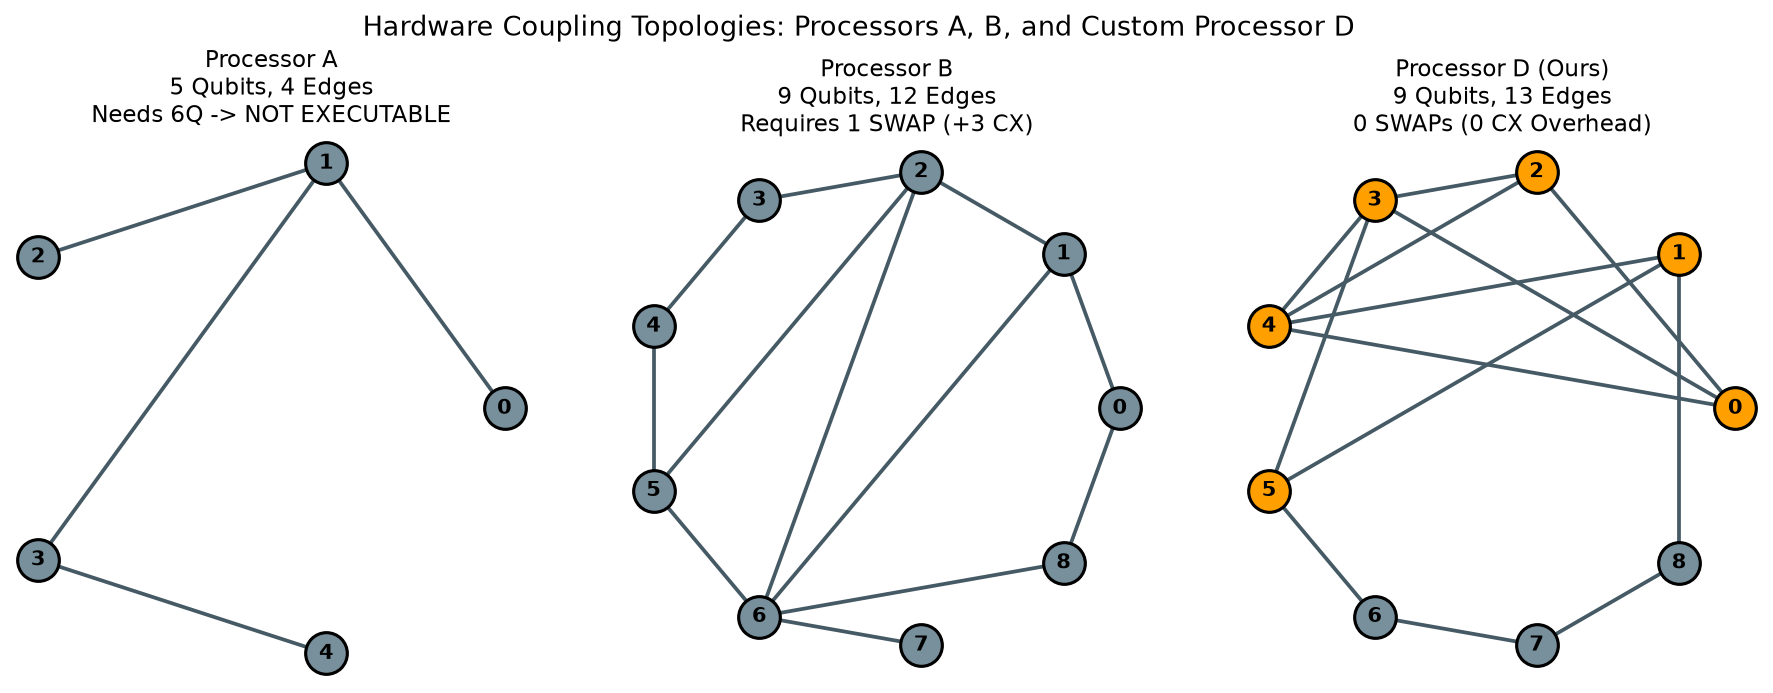

In [4]:
# Section 5.1: Processor D Validation
proc_d = load_processor("processors/processor_D.json")
errs = validate_processor_d(proc_d, required_qubits=6)
print(f"Processor D Rule Validation: {'PASS (0 violations)' if not errs else errs}")
print(f"Num Qubits:      {proc_d['num_qubits']}")
print(f"Num Edges:       {len(proc_d['edges'])}")
print(f"Basis Gates:     {proc_d['basis_gates']}")
print(f"Noise Settings:  {proc_d['noise']}")

display(Image(filename="results/figures/processor_topologies.png"))


# Section 6: Objective 3 — QAOA Parameter Optimization & Cross-Processor Benchmarking
QAOA ($p=1$) is optimized across mandatory initialization seeds $[0, 1, 2, 3, 4]$ using COBYLA on exact statevector expectation.
Cross-processor sampling ($4096$ shots) is conducted on Processors A, B, and D.


In [5]:
# Section 6.1: Cross-Processor Benchmark Execution
from src.benchmarking import run_benchmarks

bench_data = run_benchmarks(
    processor_d_path="processors/processor_D.json",
    results_csv_path="results/tables/results.csv",
    opt_runs_csv_path="results/tables/optimization_runs.csv",
    proc_metrics_csv_path="results/tables/processor_metrics.csv",
    raw_counts_path="results/raw/qaoa_counts.json",
)

df_opt = pd.read_csv("results/tables/optimization_runs.csv")
print("=== QAOA Multi-Restart Parameter Optimization (seeds 0..4) ===")
display(df_opt)

df_results = pd.read_csv("results/tables/results.csv")
print("\n=== Cross-Processor Benchmark Comparison (results/tables/results.csv) ===")
display(df_results)


=== QAOA Multi-Restart Parameter Optimization (seeds 0..4) ===


,seed,initial_gamma,initial_beta,final_gamma,final_beta,cost_expectation,approx_ratio,iterations,success
0,0,2.001074,0.847560,2.960425,-0.407051,15.551533,0.706888,43,True
1,1,1.607935,2.985970,2.960673,4.299710,15.551037,0.706865,80,False
2,2,0.821879,0.937738,2.960452,-0.407161,15.551533,0.706888,36,True
3,3,0.269075,0.743962,-0.168020,0.332662,17.712817,0.805128,37,True
4,4,2.962698,1.606383,4.708001,0.849399,15.532392,0.706018,49,True



=== Cross-Processor Benchmark Comparison (results/tables/results.csv) ===


,problem_id,processor,condition,executable,logical_qubits,physical_qubits,logical_cx,cx,depth,two_q_depth,swaps,cx_overhead,shots,quality_metric,quality_value,p_opt,classical_optimum,random_baseline
0,PS-O1,A,ideal,False,6,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,approx_ratio,NaN,NaN,22,0.6136
1,PS-O1,A,noisy,False,6,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,approx_ratio,NaN,NaN,22,0.6136
2,PS-O1,B,ideal,True,6,9,18.0,21.0,37.0,17.0,1.0,3.0,4096.0,approx_ratio,0.8074,0.1396,22,0.6136
3,PS-O1,B,noisy,True,6,9,18.0,21.0,37.0,17.0,1.0,3.0,4096.0,approx_ratio,0.7874,0.1260,22,0.6136
4,PS-O1,D,ideal,True,6,9,18.0,18.0,29.0,14.0,0.0,0.0,4096.0,approx_ratio,0.8052,0.1384,22,0.6136
5,PS-O1,D,noisy,True,6,9,18.0,18.0,29.0,14.0,0.0,0.0,4096.0,approx_ratio,0.7862,0.1250,22,0.6136


=== Circuit Resource Comparison: B vs D ===


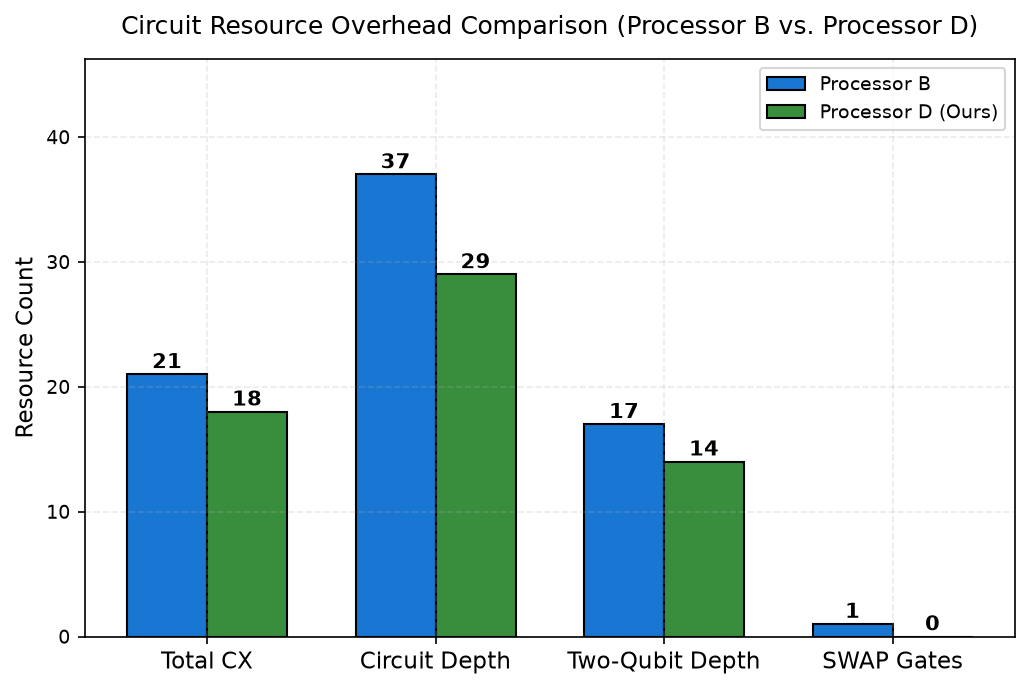

=== QAOA Sampled Cut Weight Distribution ===


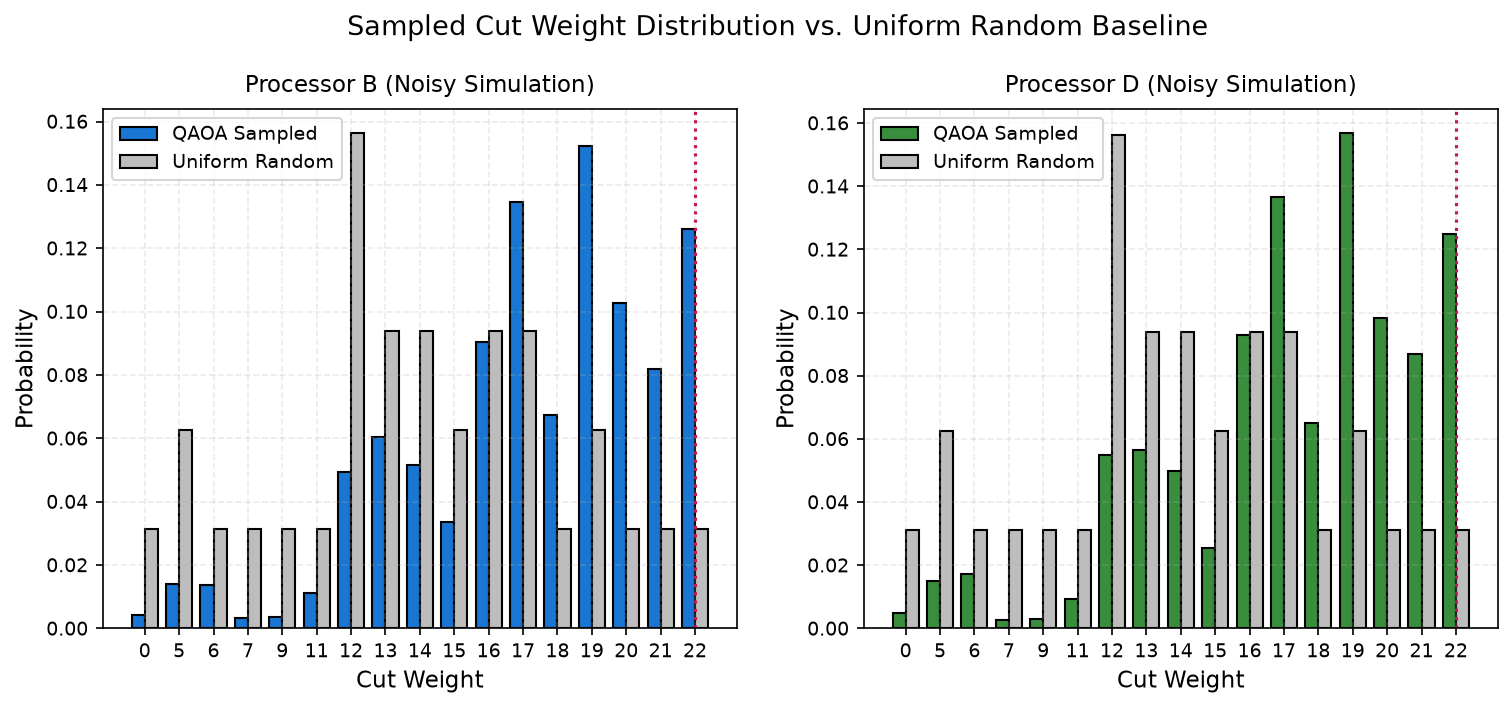

=== QAOA Parameter Energy Landscape ===


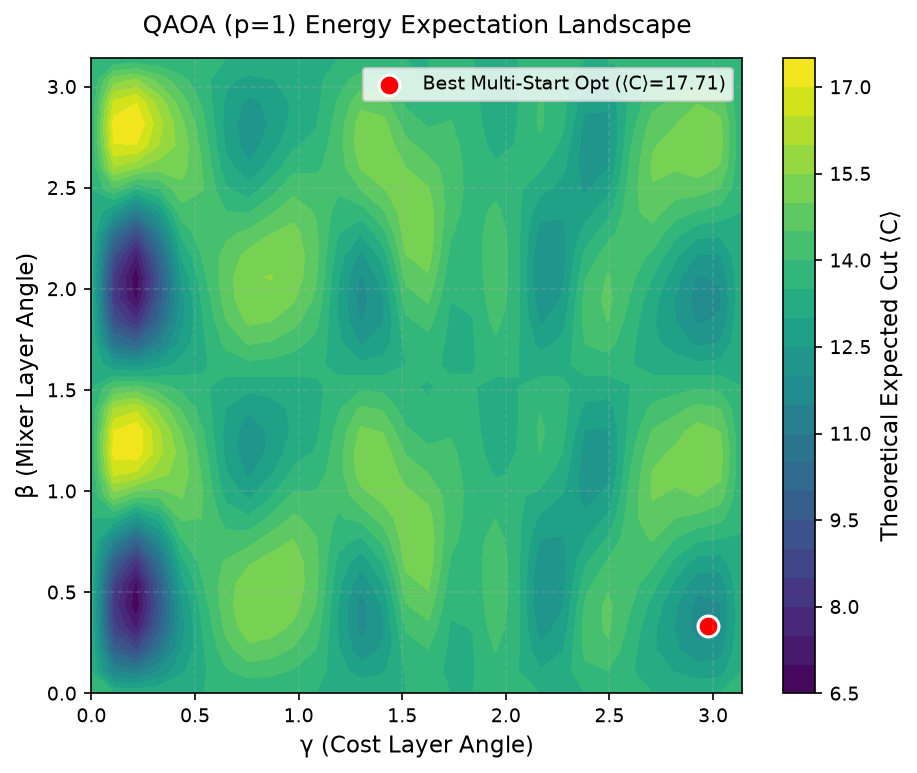

=== Architecture Trade-Off Map ===


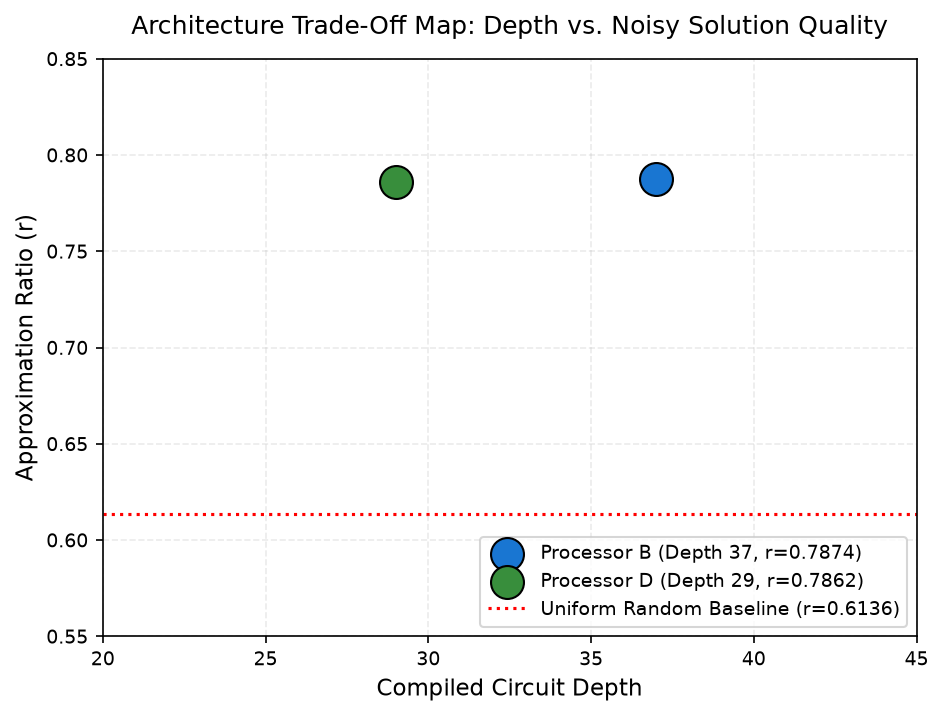

In [6]:
# Section 7: Scientific Visualizations
print("=== Circuit Resource Comparison: B vs D ===")
display(Image(filename="results/figures/processor_resource_comparison.png"))

print("=== QAOA Sampled Cut Weight Distribution ===")
display(Image(filename="results/figures/qaoa_cut_distribution.png"))

print("=== QAOA Parameter Energy Landscape ===")
display(Image(filename="results/figures/qaoa_parameter_landscape.png"))

print("=== Architecture Trade-Off Map ===")
display(Image(filename="results/figures/architecture_tradeoff_map.png"))


# Section 8: Scientific Analysis, Trade-Offs & Conclusion

### 8.1 Key Findings & Discussion
1. **Processor A Infeasibility:** Correctly identified as not executable ($5 < 6$ qubits).
2. **SWAP Overhead Elimination:** Processor B incurs 1 SWAP (+3 CX gates, 16.7% two-qubit overhead), while Processor D achieves **0 SWAPs** and **0 CX overhead**, compressing depth from 37 to 29 (-21.6%) and two-qubit depth from 17 to 14 (-17.6%).
3. **Noisy Solution Quality & Statistical Comparability:** Under official noise ($p_1=0.001, p_2=0.005, p_{\text{readout}}=0.01$), Processor B achieves sampled mean cut $\langle C \rangle = 17.3220 \pm 0.0598$ ($r = 0.7874 \pm 0.0027$) and Processor D yields $\langle C \rangle = 17.2971 \pm 0.0612$ ($r = 0.7862 \pm 0.0028$). The difference $\Delta \langle C \rangle = 0.0249 \pm 0.0856 \implies \Delta r = 0.0011 \pm 0.0039$ ($z = 0.2910\sigma, p = 0.7711$) indicates that the sampled mean cuts are statistically indistinguishable under 4096 shots. Importantly, this equivalence in sampled mean does not imply that the full 64-element output probability distributions are identical. Both provide a $4.0\times$ probability enhancement of sampling the optimal partition ($12.5\%$ vs. $3.125\%$). Processor D's zero-SWAP compilation represents future architectural potential if scaled to higher depths ($p \ge 2$).
4. **Bell-State Tomography:** Fidelity drops from $0.9633 \pm 0.0021$ on adjacent physical pair $(0, 2)$ to $0.9420 \pm 0.0026$ on distant pair $(0, 7)$ ($d=4$, 10 CX gates), validating simulated two-qubit routing error accumulation at $6.37\sigma$ significance.

### 8.2 Reproducibility & Integrity
All experiments are reproducible deterministically using `scripts/run_all.py` and validated by automated pytest suites.
